# code_029 · Self-supervision and partial supervision

**Book:** section 6.3. These are synthetic mechanism experiments, not observed structural performance, safety assessment, a causal study or an estimator leaderboard. Each experiment states which cases are unseen and which outcomes are available. Fits and preprocessing use training observations only. Development curves support diagnosis; final outcomes are opened only after the stated rule is fixed. Constructed identities and stress cases are not held-out population estimates.

Restart and run all cells. All imports, helpers and data generation are here; no ordinary-run files, network, API key, GPU or private module is required. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [traceability guide](../CHAPTER_06_GUIDE.md), [execution evidence](../CHAPTER_06_EXECUTION.md) and [permanent registry](../CODE_EXAMPLES.md#code_029). Reference environment: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute for execution and 30–60 minutes for interpretation. These scoped labs disclose relevant controls rather than cover every constructor parameter.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=629;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 629


<a id="masking"></a>
## Historical observations supply a pretext target

Six sensor channels measure two latent coordinates plus noise sd .08 in fixed reference units. Generate 400 historical source snapshots, separate 200 downstream training, 80 development and 120 final members. Fit a scaler on source snapshots only. No downstream development/final inputs enter representation training (an inductive, not transductive contract). Historical source channels all existed before the downstream inspection task. Randomly hide 25% of channels; zero-fill in standardized coordinates and append six binary missingness indicators. A clean hidden value is the target, never an encoder input.

Train a tanh 12→3 encoder and linear 3→6 decoder with masked-only squared error. Fixed 900 updates, full source batch, rate .08, weight initial sd .12. A fixed mask is used only to report a training probe curve, not to choose stopping. This is self-supervised pretraining without inspection labels.


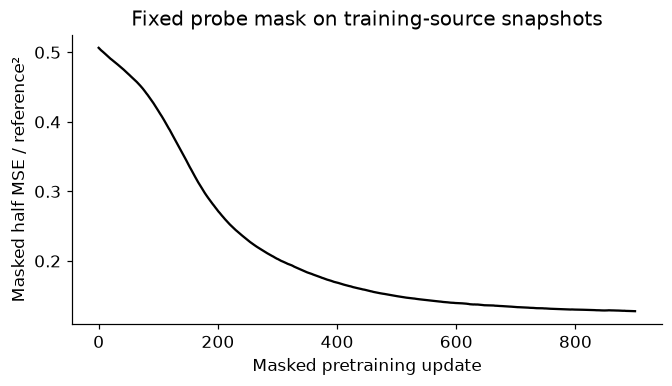

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from scipy.special import expit,logsumexp
mix=np.array([[1.,0.],[.7,.3],[-.3,1.],[.4,-.8],[1.,.5],[-.6,.4]])
latent=rng.normal(size=(800,2));raw=latent@mix.T+rng.normal(0,.08,(800,6));target=rng.binomial(1,expit(-.4+1.6*latent[:,0]-.6*latent[:,1]))
source=np.arange(400);down=np.arange(400,600);dev=np.arange(600,680);final=np.arange(680,800);human=down[:40];unlabelled=down[40:]
scaler=StandardScaler().fit(raw[source]);Z=scaler.transform(raw)
assert not set(source)&set(down) and not set(down)&set(dev) and not set(down)&set(final)
assert np.allclose(scaler.mean_,raw[source].mean(0)) and len(human)==40
W=rng.normal(0,.12,(12,3));b=np.zeros(3);V=rng.normal(0,.12,(3,6));c=np.zeros(6)
def masked_input(z,mask):return np.column_stack([np.where(mask,0.,z),mask.astype(float)])
def encode(z):return np.tanh(masked_input(z,np.zeros_like(z,dtype=bool))@W+b)
def masked_loss(z,mask):
 h=np.tanh(masked_input(z,mask)@W+b);res=h@V+c-z
 return float(.5*np.sum((res*mask)**2)/mask.sum())
probe=rng.random((400,6))<.25;history=[masked_loss(Z[source],probe)]
for step in range(900):
 mask=rng.random((400,6))<.25;inputs=masked_input(Z[source],mask);h=np.tanh(inputs@W+b);res=(h@V+c-Z[source])*mask/mask.sum()
 dV=h.T@res;dc=res.sum(0);dh=(res@V.T)*(1-h*h);dW=inputs.T@dh;db=dh.sum(0)
 W-=.08*dW;b-=.08*db;V-=.08*dV;c-=.08*dc
 history.append(masked_loss(Z[source],probe))
assert history[-1]<history[0] and np.isfinite(history).all()
check=masked_input(Z[source],probe);assert np.all(check[:,:6][probe]==0.) and np.array_equal(check[:,6:],probe)
fig,ax=plt.subplots(figsize=(6,3.4));ax.plot(history,'k-');ax.set(xlabel='Masked pretraining update',ylabel='Masked half MSE / reference²',title='Fixed probe mask on training-source snapshots');plt.show()
RESULTS['masked_probe_initial_final']=[float(history[0]),float(history[-1])]


<a id="contrastive"></a>
## A contrastive signal needs a declared positive relation

Use two small independent sensor-noise perturbations (sd .02 standardized units) of the same 48 historical snapshots as positives. This assumes that such perturbations preserve the information of interest. Other rows act as negatives, which may include the same underlying regime. Compute a one-direction cross-batch contrastive loss with cosine similarities and fixed temperature .2 using the frozen masked-pretrained encoder. This cell evaluates an actual contrastive objective; it does not claim that the encoder was optimized by it or implement the full SimCLR method.

If every embedding is the same, the loss is log(batch size), not a perfect solution. Merely reducing this loss would still not prove inspection usefulness.


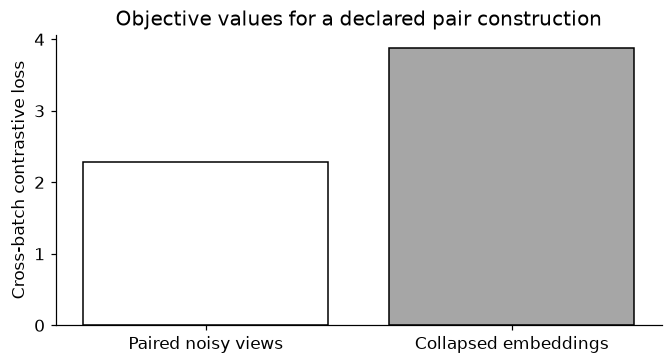

In [3]:
def normalize(h):return h/np.maximum(np.linalg.norm(h,axis=1,keepdims=True),1e-12)
def contrastive(a,b,temp=.2):
 scores=normalize(a)@normalize(b).T/temp
 return float(np.mean(logsumexp(scores,axis=1)-np.diag(scores)))
view1=Z[source[:48]]+rng.normal(0,.02,(48,6));view2=Z[source[:48]]+rng.normal(0,.02,(48,6))
ha=encode(view1);hb=encode(view2);positive_loss=contrastive(ha,hb);collapsed=contrastive(np.ones((48,3)),np.ones((48,3)))
assert np.isclose(collapsed,np.log(48)) and np.isfinite(positive_loss)
consistency=float(np.mean(np.sum((normalize(ha)-normalize(hb))**2,axis=1)))
assert consistency>=0 and ha.shape==(48,3)
fig,ax=plt.subplots(figsize=(6,3.2));ax.bar(['Paired noisy views','Collapsed embeddings'],[positive_loss,collapsed],color=['white','.65'],edgecolor='black');ax.set(ylabel='Cross-batch contrastive loss',title='Objective values for a declared pair construction');plt.show()
RESULTS['contrastive_paired_collapsed']=[positive_loss,collapsed];RESULTS['embedding_consistency_distance']=consistency


<a id="adaptation"></a>
## Sparse human labels: frozen features and actual fine-tuning

First fit LogisticRegression(C=1,solver='lbfgs',max_iter=1000) on 40 human-labelled downstream training rows using frozen features. Then copy the pretrained encoder and initialize a logistic head from that fit. Optimize binary cross entropy on the same 40 labels for 600 updates at rate .03, updating encoder and head weights. Decoder weights are not used. No development/final outcome chooses a checkpoint. The two procedures share pretraining but change different stored state.


In [4]:
frozen=LogisticRegression(C=1.,solver='lbfgs',max_iter=1000).fit(encode(Z[human]),target[human]);savedW=W.copy();savedb=b.copy()
Wfine=W.copy();bfine=b.copy();head=frozen.coef_[0].copy();intercept=float(frozen.intercept_[0]);inputs=masked_input(Z[human],np.zeros((40,6),dtype=bool))
for step in range(600):
 h=np.tanh(inputs@Wfine+bfine);p=expit(h@head+intercept);r=(p-target[human])/len(human);dh=r[:,None]*head[None,:]*(1-h*h)
 dhead=h.T@r;di=r.sum();dW=inputs.T@dh;db=dh.sum(0)
 Wfine-=.03*dW;bfine-=.03*db;head-=.03*dhead;intercept-=.03*di
assert np.array_equal(W,savedW) and np.array_equal(b,savedb) and not np.allclose(Wfine,W)
assert frozen.n_iter_[0]<1000 and np.isfinite(Wfine).all()
def fine_probability(z):return expit(np.tanh(masked_input(z,np.zeros_like(z,dtype=bool))@Wfine+bfine)@head+intercept)


<a id="partial"></a>
## Pseudo-labels are model claims, not new human findings

Use the frozen-feature human-label model as a teacher. Eligible unlabelled rows are the 160 downstream training cases only. Keep teacher predictions with confidence >=.85 and unchanged hard prediction after small sensor perturbation. Fit one student pass using human labels (weight 1) plus selected pseudo-labels (weight .3). A prediction-consistency penalty is also computed explicitly as mean squared probability change, but is not silently added to this student objective. This is a scoped semi-supervised self-training experiment, not calibrated-confidence proof. If no pseudo-label passes, retain the supervised teacher.


In [5]:
teacher=frozen.predict_proba(encode(Z[unlabelled]))[:,1];perturbed=frozen.predict_proba(encode(Z[unlabelled]+rng.normal(0,.02,(160,6))))[:,1]
keep=(np.maximum(teacher,1-teacher)>=.85)&((teacher>=.5)==(perturbed>=.5));pseudo_ids=unlabelled[keep];pseudo=(teacher[keep]>=.5).astype(int)
assert set(pseudo_ids)<=set(unlabelled) and not set(pseudo_ids)&set(dev) and not set(pseudo_ids)&set(final)
student=frozen
if len(pseudo_ids):
 student=LogisticRegression(C=1.,solver='lbfgs',max_iter=1000).fit(np.vstack([encode(Z[human]),encode(Z[pseudo_ids])]),np.r_[target[human],pseudo],sample_weight=np.r_[np.ones(40),np.full(len(pseudo),.3)])
assert len(pseudo)==len(pseudo_ids) and np.isin(pseudo,[0,1]).all()
RESULTS['pseudo_labels_selected']=len(pseudo_ids);RESULTS['teacher_prediction_consistency_MSE']=float(np.mean((teacher-perturbed)**2))
print('Selected training-only pseudo-labels:',len(pseudo_ids),'development fine-tune probability mean:',fine_probability(Z[dev]).mean())


Selected training-only pseudo-labels: 38 development fine-tune probability mean: 0.4194858471621673


<a id="final"></a>
## Fixed procedures, final outcomes once

Report binary log loss separately for frozen-feature supervised fitting, fine-tuning and one-pass semi-supervised self-training. No winner is selected from final outcomes. Differences on this synthetic sample do not isolate pretraining benefit: there is no equally budgeted from-scratch comparison. Preserve fresh final evidence for extensions.


In [6]:
def logloss(y,p):
 p=np.clip(p,1e-12,1-1e-12);return float(-np.mean(y*np.log(p)+(1-y)*np.log1p(-p)))
metrics={'frozen_features':logloss(target[final],frozen.predict_proba(encode(Z[final]))[:,1]),'fine_tuned':logloss(target[final],fine_probability(Z[final])),'semi_supervised':logloss(target[final],student.predict_proba(encode(Z[final]))[:,1])}
assert np.isfinite(list(metrics.values())).all() and np.array_equal(W,savedW)
RESULTS['final_binary_log_loss']=metrics;print(metrics)


{'frozen_features': 0.5519200844744722, 'fine_tuned': 0.5749398969854592, 'semi_supervised': 0.5615449171425718}


<a id="exercises"></a>
## Exercises and hints

1. Construct masks from later readings and show exactly when a forecasting pretext task would cross its prediction boundary.
2. Change positive-pair construction to mix different buildings. Which information would the contrastive objective erase?
3. Vary pseudo-label threshold on development evidence; inspect selection by subgroup and keep fresh final outcomes.
4. Compare the fine-tuned model with a budget-matched scratch fit before claiming a pretraining benefit.
5. Change consistency perturbations so that they alter the target. Explain why the regularizer is then misleading.

**Hints:** self-supervision names target construction; semi-supervision names a combination of labelled/unlabelled training evidence. The contrastive cell is an objective check, not contrastively trained weights. The reference [contrastive paper](https://proceedings.mlr.press/v119/chen20j.html) uses a different full method; this lab uses only structured sensor vectors. See official [self-training documentation](https://scikit-learn.org/1.9/modules/generated/sklearn.semi_supervised.SelfTrainingClassifier.html) for iterative variants beyond this explicit one-pass implementation.


In [7]:
summary={'example_id':'code_029','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['masked historical reconstruction with explicit mask', 'actual encoder pretraining and sparse-label fine tuning', 'contrastive positive-pair loss and collapse check', 'pseudo-label provenance and consistency', 'independent final assessment without final-input pretraining'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["masked historical reconstruction with explicit mask", "actual encoder pretraining and sparse-label fine tuning", "contrastive positive-pair loss and collapse check", "pseudo-label provenance and consistency", "independent final assessment without final-input pretraining"], "elapsed_seconds": 0.286, "example_id": "code_029", "hardware": "Darwin arm64 CPU", "results": {"contrastive_paired_collapsed": [2.283481609413014, 3.871201010907892], "embedding_consistency_distance": 0.00953347399825087, "final_binary_log_loss": {"fine_tuned": 0.5749398969854592, "frozen_features": 0.5519200844744722, "semi_supervised": 0.5615449171425718}, "masked_probe_initial_final": [0.5063965593030453, 0.12773696963384054], "pseudo_labels_selected": 38, "teacher_prediction_consistency_MSE": 1.8015000452831338e-05}, "seed": 629, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.